# Covariate-aware substrate recovery in voxel space — a convolutional VAE

Lesion–symptom mapping asks *which regions, when damaged, cause a deficit* — the neural
**substrate**. This tutorial works in **4 mm MNI voxel space** and compares four recovery methods:

* **VLSM** — mass-univariate Welch t-test + permutation FDR.
* **SVR-LSM** — multivariate RBF support-vector regression + back-projection (Zhang 2014).
* **MLP-VAE** — the two-arm variational auto-encoder of *vae_lesion_deficit* (membership × importance).
* **Conv-VAE** — the same two-arm VAE with a **3D-convolutional** encoder/decoder (spatial prior).

Real deficits also depend on **covariates** (age, …) that are *confounded* with the lesion
(older patients tend to have larger lesions), so each method is run **covariate-blind vs
covariate-aware**. Two headline findings, on 512 real KCH stroke lesions:

1. **The conv-VAE recovers the substrate best** — the 3D spatial prior beats the flat MLP and the
   classical methods.
2. **Covariate-awareness helps the conv-VAE** (and it leaks the least confound bias), whereas the
   linear methods over-correct.

The heavy conv-VAE is trained on a GPU; its numbers here are **precomputed** (`voxel_results.json`),
while the fast methods run live below. Model/baseline logic lives in importable modules
(`voxel_data.py`, `baselines.py`, `mlp_vae.py`, `conv_vae.py`, `covariate_deficits.py`).

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt

import baselines as B
from voxel_data import VoxelData
from covariate_deficits import make_covariate_benchmark_deficits, BENCHMARK_RULES
from mlp_vae import fit_parcel_vae

# Live-demo knobs (fast methods only; the conv-VAE is precomputed — see below).
N_PERM = 500       # permutations for VLSM/SVR significance (2000 used for the shipped results)
VAE_EPOCHS = 200   # MLP-VAE epochs for the live demo (500 for the shipped results)
SEED = 0
RESULTS = json.loads((open("voxel_results.json").read()))

## 1. Data — a coverage-restricted 4 mm voxel set

512 real KCH stroke lesions resampled to the 4 mm NeuroQuery grid, restricted to the
**coverage mask** (voxels lesioned in ≥ 10 patients — standard voxel-LSM practice), giving
`V_cov` analysis voxels. Six NeuroQuery substrates are the ground truth.

In [2]:
data = VoxelData.load("voxel_data_sample/voxel_ds.npz")
print(f"V_cov = {data.n_voxels} voxels   N = {data.n_patients} patients")
for name, m in data.substrates.items():
    cx = data.centroids[m][:, 0].mean()
    print(f"  {name:32s} |M| = {int(m.sum()):4d}   mean x = {cx:+6.1f} mm")

V_cov = 2541 voxels   N = 512 patients
  gaze                             |M| =  127   mean x =  +21.8 mm
  language                         |M| =  127   mean x =  -45.5 mm
  dorsal_premotor                  |M| =  127   mean x =  -32.0 mm
  early_visual                     |M| =  127   mean x =   -6.4 mm
  progressive_nonfluent_aphasia    |M| =  127   mean x =  -24.4 mm
  spatial_attention                |M| =  127   mean x =  -12.7 mm


## 2. The four methods

All four return a per-voxel score and a self-thresholded mask. Covariate control:

* **VLSM / SVR-LSM** — *partialing-out*: the behaviour is residualized on `[1, covariates]`
  before the test/fit (the DeMarco & Turkeltaub 2018 standard; appending covariates as SVR
  features is mis-scaled and inert — see the note in `baselines.py`).
* **VAEs** — a covariate head (`β` main + `γ` interaction) added to the deficit predictor; the
  covariates enter the **head only**, never the encoder, so the substrate readout `E[σ(γ)·w]`
  stays covariate-invariant.

The conv-VAE swaps the flat MLP for a 3D-conv encoder/decoder (CoordConv, label-as-volume,
downsample/upsample blocks) — the spatial prior is what voxel space needed:

In [3]:
import conv_vae
print(conv_vae.ConvLesionDeficitVAE.__doc__.strip().split(chr(10))[0])
print(conv_vae.fit_conv_vae.__doc__.strip().split(chr(10)+chr(10))[0])

3D-conv two-arm VAE. Inference decoder emits ``(γ, w)`` per voxel; deficit uses ``E[X·σ(γ)·w]``.
Fit the 3D-conv two-arm VAE on one episode; return the ``(V_cov,)`` recovered substrate map.


## 3. The covariate-conditioned deficit

`make_covariate_benchmark_deficits` builds `severity = g·clip(1+β_int·age) + β_main·age`, with
**age** constructed so `corr(age, lesion_volume) ≈ ρ` — the lesion-volume confound expressed
through age. Positives are the top `target_rate` by severity.

In [4]:
SUB = "dorsal_premotor"
m = data.substrates[SUB]
deficits, cov = make_covariate_benchmark_deficits(
    data.X, m.astype(np.float32), data.centroids, K_parcel=data.n_voxels,
    beta_main=0.5, beta_int=0.5, rho=0.5, seed=SEED)
age, vol = cov[:, 0], data.X.sum(1)
print(f"substrate {SUB}:  corr(age, lesion volume) = {np.corrcoef(age, vol)[0,1]:+.3f}  (rho=0.5)")
for r in BENCHMARK_RULES:
    pos = deficits[r] > 0.5
    print(f"  {r:10s} n_pos={int(pos.sum()):3d}  mean age(+)= {age[pos].mean():+.2f} vs "
          f"age(-)= {age[~pos].mean():+.2f}")

substrate dorsal_premotor:  corr(age, lesion volume) = +0.505  (rho=0.5)
  coverage   n_pos= 61  mean age(+)= +1.11 vs age(-)= -0.15
  bool_OR    n_pos= 61  mean age(+)= +1.06 vs age(-)= -0.14
  hub_spoke  n_pos= 61  mean age(+)= +1.16 vs age(-)= -0.16
  bool_AND   n_pos= 61  mean age(+)= +1.61 vs age(-)= -0.22


## 4. Blind vs aware — the fast methods, live

VLSM, SVR-LSM and the MLP-VAE run live on one substrate (the conv-VAE is precomputed in §5).
We score **Dice@k** (top-|M| ranking), **binary Dice** (self-thresholded mask), and **leakage**
(how much off-target weight tracks the age confound; lower = less biased).

In [5]:
RULE = "coverage"
y = deficits[RULE]
k = int(m.sum())
exposure = B.age_exposure(data.X, cov)

def run(method, cov_arg):
    if method == "vlsm":
        mask = B.vlsm_binary(data.X, y, delta=0.10, n_perm=N_PERM, cov=cov_arg, seed=SEED)[0]
        score = B.vlsm_stat(data.X, y, delta=0.10, cov=cov_arg)
    elif method == "svr":
        mask = B.svr_binary(data.X, y, n_perm=N_PERM, cov=cov_arg, seed=SEED)[0]
        score = B.svr_weights(data.X, y, cov=cov_arg)
    else:
        score = fit_parcel_vae(data.X, y, cov=cov_arg, epochs=VAE_EPOCHS, seed=SEED)
        mask = B.focal_mass_mask(score)
    return score, mask

print(f"{SUB} / {RULE}  (|M|={k})\n")
print(f"{'method':8s} {'Dice@k bl':>10s}{'aw':>7s}  {'binDice bl':>11s}{'aw':>7s}  {'leak bl':>9s}{'aw':>7s}")
for method in ("vlsm", "svr", "mlp_vae"):
    sb, mb_ = run(method, None); sa, ma = run(method, cov)
    print(f"{method:8s} {B.dice_at_k(sb,m,k):>10.3f}{B.dice_at_k(sa,m,k):>7.3f}  "
          f"{B.dice(mb_,m):>11.3f}{B.dice(ma,m):>7.3f}  "
          f"{B.leakage(sb,m,exposure):>9.3f}{B.leakage(sa,m,exposure):>7.3f}")

dorsal_premotor / coverage  (|M|=127)

method    Dice@k bl     aw   binDice bl     aw    leak bl     aw


vlsm          0.150  0.220        0.173  0.203      0.370  0.640


svr           0.417  0.425        0.000  0.000      0.422  0.092


mlp_vae       0.362  0.425        0.362  0.434      0.414  0.322


## 5. The conv-VAE (GPU) — precomputed

Training the conv-VAE per episode is GPU-work (minutes each; hours for the full grid), so it
isn't run live. To reproduce, on a GPU:

```python
from conv_vae import fit_conv_vae
score = fit_conv_vae(data.X, y, mask_idx=data.mask_idx, vol_shape=data.vol_shape,
                     cov=cov, epochs=300, batch=64, start_dims=16, num_down=3, seed=0)
```

Below are the shipped results — **means over all 6 substrates × 4 rules, n_perm=2000, conv 300
epochs** (jobs 188560 blind / 188628 covariate).

In [6]:
M = RESULTS["meta"]["methods"]
bl = RESULTS["blind_mean"]; cm = RESULTS["cov_mean"]
print("=== BLIND substrate recovery (MEAN) ===")
print(f"{'metric':12s}" + "".join(f"{x:>10s}" for x in M))
for key, lab in [("dice_k", "Dice@k"), ("dice_bin", "binary Dice")]:
    print(f"{lab:12s}" + "".join(f"{bl[key][x]:>10.3f}" for x in M))
print("\n=== COVARIATE blind -> aware (MEAN) ===")
print(f"{'metric':12s}" + "".join(f"{x+'_bl':>10s}{x+'_aw':>7s}" for x in M))
for key, lab in [("dice_k", "Dice@k"), ("dice_bin", "binary Dice"), ("leakage", "leakage")]:
    print(f"{lab:12s}" + "".join(f"{cm[key][x][0]:>10.3f}{cm[key][x][1]:>7.3f}" for x in M))

=== BLIND substrate recovery (MEAN) ===
metric            vlsm       svr   mlp_vae  conv_vae
Dice@k           0.391     0.437     0.376     0.456
binary Dice      0.398     0.300     0.366     0.420

=== COVARIATE blind -> aware (MEAN) ===
metric         vlsm_blvlsm_aw    svr_bl svr_awmlp_vae_blmlp_vae_awconv_vae_blconv_vae_aw
Dice@k           0.233  0.340     0.360  0.324     0.321  0.343     0.438  0.465
binary Dice      0.258  0.281     0.257  0.342     0.283  0.303     0.334  0.373
leakage          0.404  0.564     0.349 -0.038     0.179  0.072     0.140  0.057


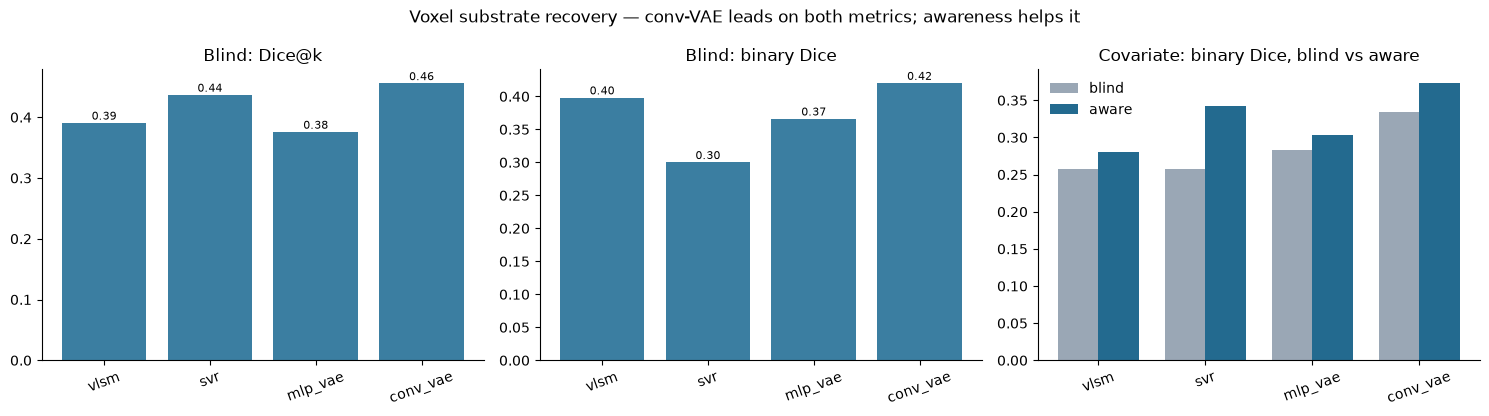

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2)); xpos = np.arange(len(M)); w = 0.38
# blind: Dice@k and binary Dice
for ax, key, title in [(axes[0], "dice_k", "Blind: Dice@k"), (axes[1], "dice_bin", "Blind: binary Dice")]:
    ax.bar(xpos, [bl[key][x] for x in M], color="#3b7ea1")
    for i, x in enumerate(M): ax.text(i, bl[key][x]+0.005, f"{bl[key][x]:.2f}", ha="center", fontsize=8)
    ax.set_xticks(xpos); ax.set_xticklabels(M, rotation=20); ax.set_title(title)
    ax.spines[["top","right"]].set_visible(False)
# covariate binary Dice blind vs aware
ax = axes[2]
b = [cm["dice_bin"][x][0] for x in M]; a = [cm["dice_bin"][x][1] for x in M]
ax.bar(xpos-w/2, b, w, label="blind", color="#9aa7b5"); ax.bar(xpos+w/2, a, w, label="aware", color="#236a8f")
ax.set_xticks(xpos); ax.set_xticklabels(M, rotation=20); ax.set_title("Covariate: binary Dice, blind vs aware")
ax.legend(frameon=False); ax.spines[["top","right"]].set_visible(False)
fig.suptitle("Voxel substrate recovery — conv-VAE leads on both metrics; awareness helps it")
plt.tight_layout(); plt.show()

## 6. What recovery looks like — glass brains

Self-thresholded recovery vs truth (blue = truth, red = recovered, purple = overlap) on the MNI
brain, four methods × blind/aware. VLSM and SVR **flood** (hundreds of voxels vs |M|=127); the
MLP-VAE self-sizes; the **conv-VAE is tightest and most on-target**.

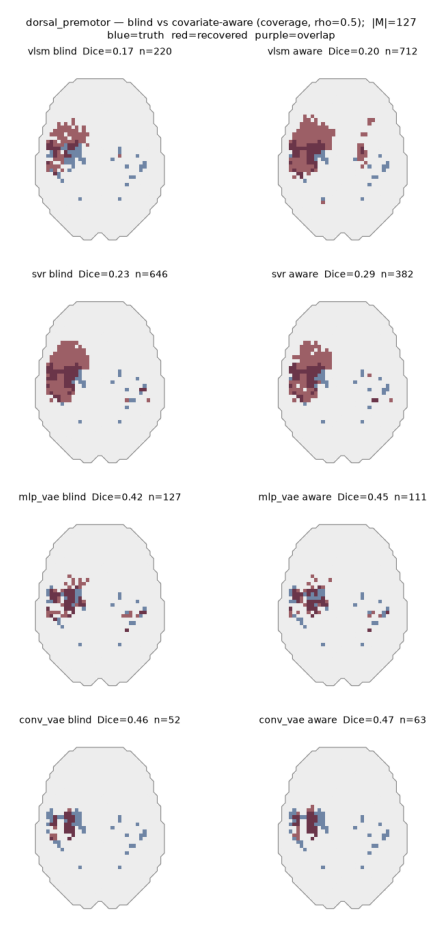

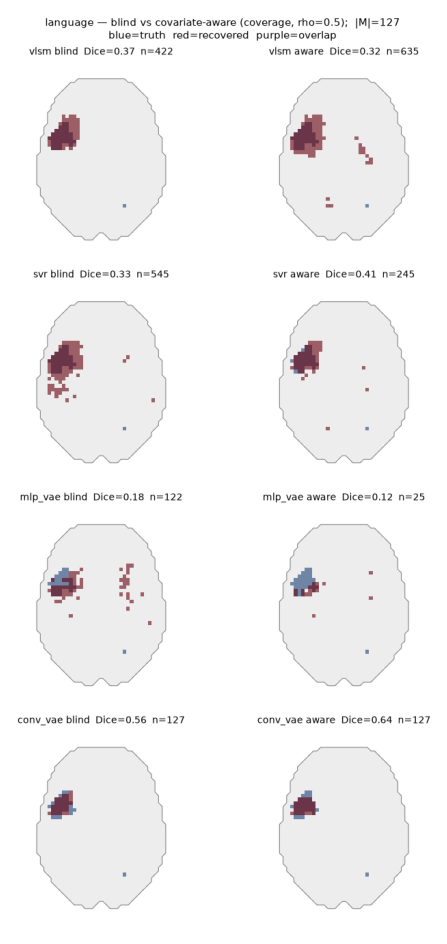

In [8]:
for name in ("dorsal_premotor", "language"):
    img = plt.imread(f"imgs/voxel_glassbrain_{name}.png")
    fig, ax = plt.subplots(figsize=(7.5, 12)); ax.imshow(img); ax.axis("off"); plt.show()

## 7. Takeaways

- **The 3D spatial prior wins.** The conv-VAE is the best recoverer in voxel space — Dice@k 0.456
  and binary Dice 0.420 blind, beating the flat MLP-VAE (0.376 / 0.366) and the classical methods.
  Locality + parameter-sharing is what the flat MLP lacked.
- **Covariate-awareness helps the conv-VAE** (Dice@k 0.438→0.465, binary 0.334→0.373) and it leaks
  the least confound bias (0.140→0.057). The **linear methods over-correct**: VLSM's leakage *rises*
  (0.404→0.564), SVR trades ranking for deployment — because residualizing an age that is collinear
  with lesion volume also strips substrate signal (a mass-univariate can't disentangle them; the
  multivariate/latent methods can).
- **Do covariate control the standard way** — *partial out* the behaviour, don't append covariates
  as features (mis-scaled and inert).